# Example 5.2 — Kinase selectivity panel of four BCR-ABL inhibitors

A reproducible record of an AI-assisted BindingDB analysis: each prompt, the BindingDB tool calls that answered it with their recorded results, the answer, and its figures. Run all cells to show the recorded results, or rerun every call on your own copy of the database and check each result against the recorded one.

- **Date:** 2026-11-23
- **Model:** claude-sonnet-5-5
- **Data:** BindingDB release **202611** (`BDB-mySQL_All_202611_dmp.zip`, SHA-256 `daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381`)
- **Database build:** 2026-11-21T01:08:15+00:00, DuckDB 1.5.6
- **Derived data:** standard InChIKeys computed from SMILES by RDKit 2026.03.6; compound_property computed from SMILES (largest fragment) by RDKit 2026.03.6
- **Server:** mcp-bindingdb v0.1.17, commit [`79dae5d22c0f`](https://github.com/sbl-sdsc/mcp-bindingdb/commit/79dae5d22c0f15b8ded9b49adc8b105f0463703a)
- **Software:** python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5
- **Notebook generated:** 2026-11-24T04:55:36Z
- **Contents:** 1 exchange · 8 tool calls · 1 figure · 1 code cell

### How to run

Keep the notebook in its folder, which holds everything it needs: `requirements.txt` (mcp-bindingdb at its commit and the versions of the packages it needs), the recorded results in `data/`, the figures in `figures/` and the analysis code the notebook imports (`kinase_selectivity_heatmap.py`). With [uv](https://docs.astral.sh/uv/), from that folder (replace the path with yours):

```bash
cd /path/to/5.2-kinase-selectivity-panel-notebook
uv run --no-project --with-requirements requirements.txt --with jupyterlab jupyter lab 5.2-kinase-selectivity-panel-notebook.ipynb
```

then choose Run → Run All Cells. The first start installs the packages, which takes a minute or two; the cells show the recorded results, so no database is needed. Without uv: `pip install -r requirements.txt jupyterlab`, then `jupyter lab 5.2-kinase-selectivity-panel-notebook.ipynb` in the folder.

### How to rerun the calls

To rerun every BindingDB call on your own copy of release 202611 and check each result against the recorded one, set `RERUN = True` in the setup cell and run all cells, or rerun the notebook without opening Jupyter, writing a copy with the new results:

```bash
cd /path/to/5.2-kinase-selectivity-panel-notebook
BINDINGDB_RERUN=1 uv run --no-project --with-requirements requirements.txt --with nbconvert jupyter nbconvert --to notebook --execute --output 5.2-kinase-selectivity-panel-notebook-rerun.ipynb 5.2-kinase-selectivity-panel-notebook.ipynb
```

A rerun needs the database: the one `BINDINGDB_DUCKDB=/path/to/bindingdb_202611.duckdb` names (put it before `uv run`), else the newest one mcp-bindingdb built on this computer, for example for Claude Desktop. With neither, the first rerun builds one, which takes about half an hour and 2.4 GB. To build exactly release 202611, with a clone of mcp-bindingdb:

```bash
git clone https://github.com/sbl-sdsc/mcp-bindingdb.git
cd mcp-bindingdb
git checkout 79dae5d22c0f15b8ded9b49adc8b105f0463703a
scripts/build_duckdb.sh --release 202611
```

The setup cell checks the database's release and source checksum against the recorded ones.

Run as it is, each call cell shows its recorded result, read from `data/` and checked against the SHA-256 digest recorded in the cell. Rerun, it shows the new result with ✅ when it matches the recorded one (floats to 10 significant digits, ids of viewers and files left out). Calls to PubChem, RCSB or PDBe depend on those services and may differ. The prose answers are the model's and are not recomputed. Code cells hold the analysis code the model wrote; they run as written (reading the results with `replay.result(n)`, the result of Call n) and draw their figures again, which are not compared.

In [ ]:
# Shows the results recorded during the session (data/), so the notebook runs without a database. Set
# RERUN = True (or start Jupyter with BINDINGDB_RERUN=1) to rerun every BindingDB call on a local copy of
# the database instead and check it against its recorded result: see 'How to rerun the calls' above.
from mcp_bindingdb.notebook import Replay

RERUN = False
replay = Replay(release='202611', source_zip_sha256='daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381', rerun=RERUN)

Recorded with BindingDB release 202611, mcp-bindingdb v0.1.17 (commit 79dae5d22c0f)
python 3.12.7, duckdb 1.5.6, rdkit 2026.03.6, mcp 2.3.0, gemmi 0.7.5


## Exchange 1

**👤 User**

Compare imatinib, nilotinib, dasatinib and bosutinib across the kinases they've all been tested against, as a heat map of median pAffinity.

In [ ]:
# Call 1 · chemical_name_to_smiles · ran 2026-11-24 04:55:35 UTC
await replay.call(1, 'chemical_name_to_smiles', {'name': 'imatinib'},
                  sha256='ab798268598a210bd1b28860c3d648554792661ff34dba55d116c5a7fc8e6796')

**Call 1** · `chemical_name_to_smiles` · recorded result · sha256 `ab798268598a…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| imatinib | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 |

```json
{
  "query": "imatinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1",
  "inchi_key": "KTUFNOKKBVMGRW-UHFFFAOYSA-N",
  "monomerid": 13530,
  "ambiguous": false
}
```

**candidates**: 2 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 13530 | BDBM13530 | Gleevec | KTUFNOKKBVMGRW-UHFFFAOYSA-N | CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1 | 1156 |
| 31341 | BDBM31341 | IMATINIB | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Cc1ccc(cc1Nc2nccc(n2)c3cccnc3)NC(=O)c4ccc(cc4)CN5CCN(CC5)C | 0 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 2 · chemical_name_to_smiles · ran 2026-11-24 04:55:35 UTC
await replay.call(2, 'chemical_name_to_smiles', {'name': 'nilotinib'},
                  sha256='1a6d374be6286db35f0fdd3c915a65440064e325e067cf8adcbd348fa82972b8')

**Call 2** · `chemical_name_to_smiles` · recorded result · sha256 `1a6d374be628…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| nilotinib | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F |

```json
{
  "query": "nilotinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F",
  "inchi_key": "HHZIURLSWUIHRB-UHFFFAOYSA-N",
  "monomerid": 50237710,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 50237710 | BDBM50237710 | NILOTINIB | HHZIURLSWUIHRB-UHFFFAOYSA-N | Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F | 614 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 3 · chemical_name_to_smiles · ran 2026-11-24 04:55:35 UTC
await replay.call(3, 'chemical_name_to_smiles', {'name': 'dasatinib'},
                  sha256='362e0056f11b929dab3315b5512734ddd14f8181f510f7dd9e651792fbc0c689')

**Call 3** · `chemical_name_to_smiles` · recorded result · sha256 `362e0056f11b…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| dasatinib | Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl |

```json
{
  "query": "dasatinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl",
  "inchi_key": "ZBNZXTGUTAYRHI-UHFFFAOYSA-N",
  "monomerid": 13216,
  "ambiguous": true
}
```

**candidates**: 3 rows

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 13216 | BDBM13216 | DASATINIB | ZBNZXTGUTAYRHI-UHFFFAOYSA-N | Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl | 1226 |
| 31089 | BDBM31089 | DASATINIB | ZBNZXTGUTAYRHI-UHFFFAOYSA-N | Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl | 16 |
| 82130 | BDBM82130 | Dasatinib | JGPNDAHBLOQVAU-UHFFFAOYSA-N | Cc1nc(cc(n1)N1CCN(CCO)CC1)N=C1NCC(S1)C(=O)Nc1c(C)cccc1Cl \|w:16.17\| | 3 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 4 · chemical_name_to_smiles · ran 2026-11-24 04:55:36 UTC
await replay.call(4, 'chemical_name_to_smiles', {'name': 'bosutinib'},
                  sha256='e112d8470125d645e60efb0ba41bb4e8dc0c09020492de2aae28f6336c723632')

**Call 4** · `chemical_name_to_smiles` · recorded result · sha256 `e112d8470125…` · uses PubChem, whose answers can change

| name | smiles |
| --- | --- |
| bosutinib | CN1CCN(CC1)CCCOc2cc3c(cc2OC)c(c(cn3)C#N)Nc4cc(c(cc4Cl)Cl)OC |

```json
{
  "query": "bosutinib",
  "resolved": true,
  "source": "bindingdb",
  "smiles": "CN1CCN(CC1)CCCOc2cc3c(cc2OC)c(c(cn3)C#N)Nc4cc(c(cc4Cl)Cl)OC",
  "inchi_key": "UBPYILGKFZZVDX-UHFFFAOYSA-N",
  "monomerid": 4552,
  "ambiguous": false
}
```

**candidates**: 1 row

| monomerid | bdbm_id | name | inchi_key | smiles | n_activities |
| --- | --- | --- | --- | --- | --- |
| 4552 | BDBM4552 | BOSUTINIB | UBPYILGKFZZVDX-UHFFFAOYSA-N | CN1CCN(CC1)CCCOc2cc3c(cc2OC)c(c(cn3)C#N)Nc4cc(c(cc4Cl)Cl)OC | 585 |

**sources_tried**: 1 row

| source | status |
| --- | --- |
| bindingdb | found |


In [ ]:
# Call 5 · run_sql · ran 2026-11-24 04:55:36 UTC
sql = """
    SELECT c.monomerid, c.inchi_key, c.name, c.n_activities FROM compound c WHERE c.inchi_key IN (SELECT inchi_key FROM compound WHERE monomerid IN (13530,50237710,13216,4552)) ORDER BY c.inchi_key
    
"""
await replay.call(5, 'run_sql', {'sql': sql, 'max_rows': 50},
                  sha256='003ff5d44ac8a557042d0da321abd20a1aa71496148c842546ec86aa07b5ca05')

**Call 5** · `run_sql` · recorded result · sha256 `003ff5d44ac8…`

```json
{
  "order_warning": "Rows 2 and 3 tie on every ORDER BY column (inchi_key), so rows like them can swap places from run to run. End the ORDER BY with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_7 rows_

| monomerid | inchi_key | name | n_activities |
| --- | --- | --- | --- |
| 50237710 | HHZIURLSWUIHRB-UHFFFAOYSA-N | NILOTINIB | 614 |
| 13530 | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Gleevec | 1156 |
| 31341 | KTUFNOKKBVMGRW-UHFFFAOYSA-N | IMATINIB | 0 |
| 86734 | KTUFNOKKBVMGRW-UHFFFAOYSA-N | Gleevec | 66 |
| 4552 | UBPYILGKFZZVDX-UHFFFAOYSA-N | BOSUTINIB | 585 |
| 13216 | ZBNZXTGUTAYRHI-UHFFFAOYSA-N | DASATINIB | 1226 |
| 31089 | ZBNZXTGUTAYRHI-UHFFFAOYSA-N | DASATINIB | 16 |


In [ ]:
# Call 6 · run_sql · ran 2026-11-24 04:55:36 UTC
sql = """
    WITH drugs AS (SELECT * FROM (VALUES ('imatinib','KTUFNOKKBVMGRW-UHFFFAOYSA-N'),('nilotinib','HHZIURLSWUIHRB-UHFFFAOYSA-N'),('bosutinib','UBPYILGKFZZVDX-UHFFFAOYSA-N'),('dasatinib','ZBNZXTGUTAYRHI-UHFFFAOYSA-N')) t(drug, inchi_key)), kd AS (SELECT d.drug, a.uniprot, a.p_affinity, a.relation, a.articleid, a.source_id FROM activity a JOIN drugs d USING (inchi_key) WHERE a.affinity_type = 'Kd' AND a.uniprot_raw = a.uniprot AND a.organism = 'Homo sapiens' AND a.p_affinity IS NOT NULL), per AS (SELECT drug, uniprot, count(*) n, count(*) FILTER (WHERE relation = '=') n_eq, median(p_affinity) FILTER (WHERE relation = '=') med_eq, median(p_affinity) med_all FROM kd GROUP BY drug, uniprot), w AS (SELECT uniprot, count(*) ndrugs, max(coalesce(med_eq, -1)) best,
     max(CASE WHEN drug='imatinib' THEN coalesce(med_eq, med_all) END) imatinib, max(CASE WHEN drug='imatinib' THEN n END) n_imatinib, max(CASE WHEN drug='imatinib' THEN n_eq END) neq_imatinib,
     max(CASE WHEN drug='nilotinib' THEN coalesce(med_eq, med_all) END) nilotinib, max(CASE WHEN drug='nilotinib' THEN n END) n_nilotinib, max(CASE WHEN drug='nilotinib' THEN n_eq END) neq_nilotinib,
     max(CASE WHEN drug='bosutinib' THEN coalesce(med_eq, med_all) END) bosutinib, max(CASE WHEN drug='bosutinib' THEN n END) n_bosutinib, max(CASE WHEN drug='bosutinib' THEN n_eq END) neq_bosutinib,
     max(CASE WHEN drug='dasatinib' THEN coalesce(med_eq, med_all) END) dasatinib, max(CASE WHEN drug='dasatinib' THEN n END) n_dasatinib, max(CASE WHEN drug='dasatinib' THEN n_eq END) neq_dasatinib
     FROM per GROUP BY uniprot HAVING count(*)=4) SELECT count(*) n_all4, count(*) FILTER (WHERE best>=8) n_ge8 FROM w
    
"""
await replay.call(6, 'run_sql', {'sql': sql, 'max_rows': 5000},
                  sha256='29a8815df1e7e7c6e1814f91a0f4422ce46a3bffd9c538d55e1c8ae731f6b84f')

**Call 6** · `run_sql` · recorded result · sha256 `29a8815df1e7…`

_1 row_

| n_all4 | n_ge8 |
| --- | --- |
| 371 | 48 |


In [ ]:
# Call 7 · run_sql · ran 2026-11-24 04:55:36 UTC
sql = """
    WITH drugs AS (SELECT * FROM (VALUES ('imatinib','KTUFNOKKBVMGRW-UHFFFAOYSA-N'),('nilotinib','HHZIURLSWUIHRB-UHFFFAOYSA-N'),('bosutinib','UBPYILGKFZZVDX-UHFFFAOYSA-N'),('dasatinib','ZBNZXTGUTAYRHI-UHFFFAOYSA-N')) t(drug, inchi_key)), kd AS (SELECT d.drug, a.uniprot, a.p_affinity, a.relation, a.articleid, a.source_id FROM activity a JOIN drugs d USING (inchi_key) WHERE a.affinity_type = 'Kd' AND a.uniprot_raw = a.uniprot AND a.organism = 'Homo sapiens' AND a.p_affinity IS NOT NULL), per AS (SELECT drug, uniprot, count(*) n, count(*) FILTER (WHERE relation = '=') n_eq, median(p_affinity) FILTER (WHERE relation = '=') med_eq, median(p_affinity) med_all FROM kd GROUP BY drug, uniprot), w AS (SELECT uniprot, count(*) ndrugs, max(coalesce(med_eq, -1)) best,
     max(CASE WHEN drug='imatinib' THEN coalesce(med_eq, med_all) END) imatinib, max(CASE WHEN drug='imatinib' THEN n END) n_imatinib, max(CASE WHEN drug='imatinib' THEN n_eq END) neq_imatinib,
     max(CASE WHEN drug='nilotinib' THEN coalesce(med_eq, med_all) END) nilotinib, max(CASE WHEN drug='nilotinib' THEN n END) n_nilotinib, max(CASE WHEN drug='nilotinib' THEN n_eq END) neq_nilotinib,
     max(CASE WHEN drug='bosutinib' THEN coalesce(med_eq, med_all) END) bosutinib, max(CASE WHEN drug='bosutinib' THEN n END) n_bosutinib, max(CASE WHEN drug='bosutinib' THEN n_eq END) neq_bosutinib,
     max(CASE WHEN drug='dasatinib' THEN coalesce(med_eq, med_all) END) dasatinib, max(CASE WHEN drug='dasatinib' THEN n END) n_dasatinib, max(CASE WHEN drug='dasatinib' THEN n_eq END) neq_dasatinib
     FROM per GROUP BY uniprot HAVING count(*)=4) SELECT w.*, (SELECT any_value(pol.short_name) FROM target t JOIN polymer pol ON pol.polymerid=t.target_id WHERE t.uniprot_raw=w.uniprot AND t.target_kind='polymer') gene, (SELECT any_value(t.name) FROM target t WHERE t.uniprot_raw=w.uniprot AND t.target_kind='polymer') pname FROM w WHERE best>=8 ORDER BY uniprot
    
"""
await replay.call(7, 'run_sql', {'sql': sql, 'max_rows': 5000},
                  sha256='33191f98b29b7bac96794d068d8df97921a6eb34b4d4cd564b339f1c5ec7619f')

**Call 7** · `run_sql` · recorded result · sha256 `33191f98b29b…`

_48 rows_

| uniprot | ndrugs | best | imatinib | n_imatinib | neq_imatinib | nilotinib | n_nilotinib | neq_nilotinib | bosutinib | n_bosutinib | neq_bosutinib | dasatinib | n_dasatinib | neq_dasatinib | gene | pname |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| O14976 | 4 | 8.89 | 6 | 4 | 4 | 5 | 1 | 0 | 8.89 | 3 | 3 | 8.59 | 5 | 5 |  | Cyclin-G-associated kinase |
| O15197 | 4 | 8.94 | 5 | 1 | 0 | 6.3 | 1 | 1 | 5.52 | 1 | 1 | 8.94 | 2 | 2 |  | Ephrin type-B receptor 6 |
| O94804 | 4 | 8.15 | 5 | 2 | 0 | 5.17 | 1 | 1 | 8.15 | 1 | 1 | 5.92 | 2 | 2 |  | Serine/threonine-protein kinase 10 |
| O95819 | 4 | 8.09 | 5 | 2 | 0 | 5 | 1 | 0 | 8.09 | 1 | 1 | 5.51 | 3 | 3 |  | Mitogen-activated protein kinase kinase kinase kinase 4 |
| P00519 | 4 | 10.21 | 7.46 | 35 | 32 | 7.87 | 17 | 16 | 10.21 | 15 | 15 | 9.28 | 28 | 28 |  | Tyrosine-protein kinase ABL1 |
| P06239 | 4 | 9.7 | 7.4 | 5 | 5 | 7.33 | 1 | 1 | 9.23 | 1 | 1 | 9.7 | 4 | 4 |  | Tyrosine-protein kinase Lck |
| P06241 | 4 | 9.1 | 5.51 | 4 | 4 | 5.8 | 1 | 1 | 7.96 | 1 | 1 | 9.1 | 5 | 5 |  | Tyrosine-protein kinase Fyn |
| P07333 | 4 | 9.24 | 7.84 | 4 | 4 | 7.35 | 1 | 1 | 6.42 | 1 | 1 | 9.24 | 4 | 4 |  | Macrophage colony-stimulating factor 1 receptor |
| P07947 | 4 | 9.52 | 5 | 2 | 0 | 5.96 | 1 | 1 | 8.4 | 1 | 1 | 9.52 | 4 | 4 |  | Tyrosine-protein kinase Yes |
| P07948 | 4 | 9.24 | 6.05 | 3 | 2 | 7 | 1 | 1 | 8.38 | 1 | 1 | 9.24 | 4 | 4 |  | Tyrosine-protein kinase Lyn |
| P08631 | 4 | 9.46 | 5 | 2 | 0 | 6.41 | 1 | 1 | 8.47 | 1 | 1 | 9.46 | 4 | 4 |  | Tyrosine-protein kinase HCK |
| P09619 | 4 | 9.2 | 7.85 | 4 | 4 | 7.47 | 2 | 2 | 6.7 | 1 | 1 | 9.2 | 3 | 3 |  | Platelet-derived growth factor receptor beta |
| P09769 | 4 | 9.3 | 5.62 | 3 | 3 | 6.49 | 1 | 1 | 8.2 | 1 | 1 | 9.3 | 3 | 3 |  | Tyrosine-protein kinase Fgr |
| P10721 | 4 | 9.13 | 7.485 | 16 | 16 | 7.34 | 9 | 9 | 6.57 | 8 | 7 | 9.13 | 14 | 12 |  | Mast/stem cell growth factor receptor Kit |
| P12931 | 4 | 9.68 | 4.4 | 3 | 1 | 5.72 | 1 | 1 | 9 | 3 | 3 | 9.68 | 5 | 5 |  | Proto-oncogene tyrosine-protein kinase Src |
| P16234 | 4 | 9.33 | 7.51 | 3 | 3 | 6.935 | 2 | 2 | 5.29 | 1 | 1 | 9.33 | 3 | 3 |  | Platelet-derived growth factor receptor alpha |
| P21709 | 4 | 8.39 | 5 | 2 | 0 | 6.23 | 1 | 1 | 5.64 | 1 | 1 | 8.39 | 4 | 4 |  | Ephrin type-A receptor 1 |
| P21860 | 4 | 9.11 | 5 | 1 | 0 | 5 | 1 | 0 | 9.11 | 2 | 2 | 7.74 | 1 | 1 |  | Receptor tyrosine-protein kinase erbB-3 |
| P29317 | 4 | 9.07 | 5 | 2 | 0 | 6.64 | 1 | 1 | 7.74 | 1 | 1 | 9.07 | 5 | 5 |  | Ephrin type-A receptor 2 |
| P29320 | 4 | 10.03 | 5 | 2 | 0 | 6.96 | 1 | 1 | 8.24 | 1 | 1 | 10.03 | 2 | 2 |  | Ephrin type-A receptor 3 |
| P29322 | 4 | 9.62 | 5.85 | 4 | 4 | 7.43 | 1 | 1 | 8.05 | 1 | 1 | 9.62 | 3 | 3 |  | Ephrin type-A receptor 8 |
| P29323 | 4 | 9.41 | 5 | 2 | 0 | 6.19 | 1 | 1 | 8.08 | 1 | 1 | 9.41 | 4 | 4 |  | Ephrin type-B receptor 2 |
| P36507 | 4 | 8 | 5 | 2 | 0 | 5 | 1 | 0 | 8 | 1 | 1 | 5.85 | 3 | 3 |  | Dual specificity mitogen-activated protein kinase kinase 2 |
| P41240 | 4 | 9 | 5 | 2 | 0 | 5.62 | 1 | 1 | 7.49 | 1 | 1 | 9 | 3 | 3 |  | Tyrosine-protein kinase CSK |
| P42681 | 4 | 8.68 | 5 | 2 | 0 | 5 | 1 | 0 | 7.14 | 1 | 1 | 8.68 | 3 | 3 |  | Tyrosine-protein kinase TXK |
| P42684 | 4 | 9.77 | 8 | 6 | 6 | 7.59 | 1 | 1 | 8.82 | 1 | 1 | 9.77 | 4 | 4 |  | Tyrosine-protein kinase ABL2 |
| P42685 | 4 | 9.51 | 5.82 | 4 | 4 | 7.07 | 1 | 1 | 8.85 | 1 | 1 | 9.51 | 4 | 4 |  | Tyrosine-protein kinase FRK |
| P51451 | 4 | 9.68 | 6.28 | 3 | 3 | 6.3 | 1 | 1 | 8.48 | 1 | 1 | 9.68 | 3 | 3 |  | Tyrosine-protein kinase Blk |
| P51813 | 4 | 8.85 | 5 | 2 | 0 | 5 | 1 | 0 | 6.7 | 1 | 1 | 8.85 | 3 | 3 |  | Cytoplasmic tyrosine-protein kinase BMX |
| P54753 | 4 | 8.16 | 5 | 2 | 0 | 6 | 1 | 1 | 6.68 | 1 | 1 | 8.16 | 4 | 4 |  | Ephrin type-B receptor 3 |
| P54756 | 4 | 9.62 | 5 | 2 | 0 | 5.72 | 1 | 1 | 7.57 | 1 | 1 | 9.62 | 4 | 4 |  | Ephrin type-A receptor 5 |
| P54760 | 4 | 9.47 | 5 | 2 | 0 | 6.14 | 1 | 1 | 8.04 | 1 | 1 | 9.47 | 4 | 4 |  | Ephrin type-B receptor 4 |
| P54762 | 4 | 9.35 | 5 | 2 | 0 | 5.89 | 1 | 1 | 7.48 | 1 | 1 | 9.35 | 3 | 3 |  | Ephrin type-B receptor 1 |
| P54764 | 4 | 8.92 | 5 | 2 | 0 | 6.48 | 1 | 1 | 7.74 | 1 | 1 | 8.92 | 4 | 4 |  | Ephrin type-A receptor 4 |
| P57059 | 4 | 8.41 | 5 | 2 | 0 | 5 | 1 | 0 | 7.52 | 1 | 1 | 8.41 | 3 | 3 |  | Serine/threonine-protein kinase SIK1 |
| Q06187 | 4 | 8.85 | 5 | 2 | 0 | 5 | 1 | 0 | 8.32 | 1 | 1 | 8.85 | 3 | 3 |  | Tyrosine-protein kinase BTK |
| Q07912 | 4 | 8.25 | 5 | 2 | 0 | 5 | 1 | 0 | 7.54 | 1 | 1 | 8.25 | 5 | 5 |  | Activated CDC42 kinase 1 |
| Q08345 | 4 | 9.16 | 9.15 | 4 | 4 | 8.96 | 1 | 1 | 6.92 | 1 | 1 | 9.16 | 4 | 4 |  | Epithelial discoidin domain-containing receptor 1 |
| Q12851 | 4 | 8.51 | 5 | 1 | 0 | 5 | 1 | 0 | 8.51 | 1 | 1 | 5.89 | 1 | 1 |  | Mitogen-activated protein kinase kinase kinase kinase 2 |
| Q13163 | 4 | 8.48 | 5 | 1 | 0 | 6.72 | 1 | 1 | 8.09 | 1 | 1 | 8.48 | 1 | 1 |  | Dual specificity mitogen-activated protein kinase kinase 5 |
| Q13882 | 4 | 8.11 | 5 | 2 | 0 | 5 | 1 | 0 | 5 | 1 | 0 | 8.11 | 3 | 3 |  | Protein-tyrosine kinase 6 |
| Q16832 | 4 | 8.49 | 7.82 | 2 | 2 | 7.845 | 4 | 4 | 6.85 | 1 | 1 | 8.49 | 5 | 5 |  | Discoidin domain-containing receptor 2 |
| Q8IVH8 | 4 | 8.29 | 5 | 2 | 0 | 5 | 1 | 0 | 8.29 | 2 | 2 | 6.19 | 3 | 3 |  | Mitogen-activated protein kinase kinase kinase kinase 3 |
| Q8N4C8 | 4 | 8.49 | 5 | 1 | 0 | 5 | 1 | 0 | 8.49 | 1 | 1 | 6.37 | 1 | 1 |  | Misshapen-like kinase 1 |
| Q8TDR2 | 4 | 8.7 | 5 | 1 | 0 | 5 | 1 | 0 | 8.7 | 1 | 1 | 6.11 | 1 | 1 |  | Serine/threonine-protein kinase 35 |
| Q9H0K1 | 4 | 8.19 | 5 | 2 | 0 | 5 | 1 | 0 | 7.54 | 1 | 1 | 8.19 | 3 | 3 |  | Serine/threonine-protein kinase SIK2 |
| Q9H2G2 | 4 | 8.33 | 5 | 2 | 0 | 5 | 1 | 0 | 8.33 | 1 | 1 | 6.14 | 3 | 3 |  | STE20-like serine/threonine-protein kinase |
| Q9Y4K4 | 4 | 9.3 | 5 | 2 | 0 | 5 | 1 | 0 | 9.3 | 1 | 1 | 7.35 | 3 | 3 |  | Mitogen-activated protein kinase kinase kinase kinase 5 |


In [ ]:
# Call 8 · run_sql · ran 2026-11-24 04:55:36 UTC
sql = """
    WITH k AS (SELECT a.uniprot, a.source_id, a.doi, a.year, a.inchi_key FROM activity a WHERE a.inchi_key IN ('KTUFNOKKBVMGRW-UHFFFAOYSA-N','HHZIURLSWUIHRB-UHFFFAOYSA-N','UBPYILGKFZZVDX-UHFFFAOYSA-N','ZBNZXTGUTAYRHI-UHFFFAOYSA-N') AND a.affinity_type='Kd' AND a.uniprot_raw=a.uniprot AND a.organism='Homo sapiens' AND a.p_affinity IS NOT NULL AND a.uniprot IN (SELECT uniprot FROM activity WHERE inchi_key='KTUFNOKKBVMGRW-UHFFFAOYSA-N' AND affinity_type='Kd')) SELECT source_id, any_value(doi) doi, any_value(year) yr, count(*) n_kd, count(DISTINCT uniprot) n_kinases FROM k GROUP BY source_id ORDER BY n_kd DESC
    
"""
await replay.call(8, 'run_sql', {'sql': sql, 'max_rows': 20},
                  sha256='e8335120a8b322f29104568a4e5610d9f1a8a1149da1f2d83fe68b5d348cbf29')

**Call 8** · `run_sql` · recorded result · sha256 `e8335120a8b3…`

```json
{
  "order_warning": "Rows 7 and 8 tie on every ORDER BY column (n_kd), so rows like them can swap places from run to run. End the ORDER BY with a unique column (e.g. monomerid; ki_result_id, affinity_type for measurements) so the result is the same on every run and a notebook's rerun check passes."
}
```

_26 rows_

| source_id | doi | yr | n_kd | n_kinases |
| --- | --- | --- | --- | --- |
| 22037378 | 10.1038/nbt.1990 | 2011 | 1744 | 371 |
| 18183025 | 10.1038/nbt1358 | 2008 | 628 | 279 |
| aid1433 |  | 2008 | 117 | 82 |
| 29928781 | 10.1002/cmdc.201800398 |  | 23 | 22 |
| 15711537 | 10.1038/nbt1068 | 2005 | 22 | 16 |
| 30807144 | 10.1021/acs.jmedchem.8b01925 | 2019 | 9 | 9 |
| 23273517 | 10.1016/j.bmcl.2012.11.111 | 2013 | 6 | 6 |
| 28792760 | 10.1021/acs.jmedchem.7b00996 | 2017 | 6 | 3 |
| 27940419 | 10.1016/j.ejmech.2016.11.003 | 2017 | 5 | 4 |
| 24754677 | 10.1021/jm500167q | 2014 | 4 | 1 |
| 32428794 | 10.1016/j.ejmech.2020.112421 | 2020 | 4 | 4 |
| 26789553 | 10.1021/acs.jmedchem.5b01618 | 2016 | 4 | 2 |
| 33970631 | 10.1021/acs.jmedchem.1c00302 | 2022 | 3 | 3 |
| 30973735 | 10.1021/acs.jmedchem.9b00350 | 2019 | 2 | 2 |
| 21429632 | 10.1016/j.ejmech.2011.02.057 | 2011 | 2 | 1 |
| 31129055 | 10.1016/j.bmcl.2019.05.025 | 2019 | 2 | 2 |
| 25822739 | 10.1021/jm501759m | 2015 | 1 | 1 |
| 34735773 | 10.1021/acs.jmedchem.1c01030 | 2021 | 1 | 1 |
| 31188592 | 10.1021/acs.jmedchem.8b01732 | 2019 | 1 | 1 |
| 19396179 | 10.1038/nchembio.162 | 2009 | 1 | 1 |
| 32688199 | 10.1016/j.ejmech.2020.112524 | 2020 | 1 | 1 |
| 37134203 | 10.1021/acs.jmedchem.3c00319 | 2023 | 1 | 1 |
| 20153202 | 10.1016/j.bmc.2010.01.053 | 2010 | 1 | 1 |
| 39818014 | 10.1016/j.ejmech.2025.117258 |  | 1 | 1 |
| 29636220 | 10.1016/j.bmcl.2018.03.032 | 2018 | 1 | 1 |
| 25699576 | 10.1021/jm501929n | 2015 | 1 | 1 |


**Figure 1: Kd selectivity of imatinib, nilotinib, bosutinib and dasatinib across 48 human kinases.** Median pKd (-log10 Kd in M) for each drug-kinase pair, wild-type human kinases only. Kinases shown are the 48 measured for all four drugs on which at least one drug reaches median pKd >= 8; columns are hierarchically clustered (average linkage). Hatched cells: every measurement was reported as Kd > 10 uM. _(as recorded; running this cell draws it again)_

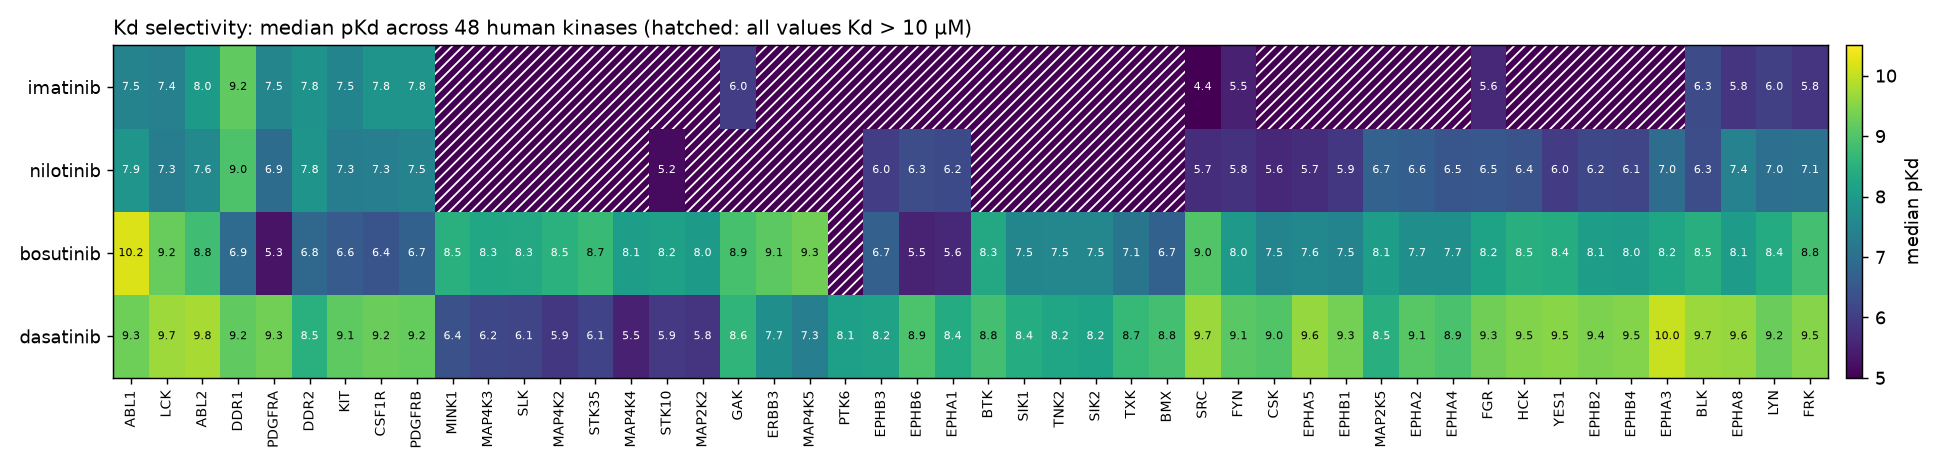

In [ ]:
# Code 1: Median pKd heat map of the 48 kinases, columns clustered, censored cells hatched
# The code is in kinase_selectivity_heatmap.py, next to this notebook (58 lines).
from kinase_selectivity_heatmap import *

plot_heatmap(replay.result(7)['rows'], 'kinase_selectivity_heatmap.png', 'heatmap_matrix_pKd.csv')

**🧠 Assistant**

**The drugs.** All four are approved BCR-ABL inhibitors. Each is pooled by its full InChIKey, so duplicate BindingDB records of the same molecule count together (imatinib has three records, dasatinib two).

| Drug | BindingDB id | SMILES | Measurements (all types, pooled) |
|---|---|---|---|
| imatinib | BDBM13530 | `CN1CCN(Cc2ccc(cc2)C(=O)Nc2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)CC1` | 1,222 |
| nilotinib | BDBM50237710 | `Cc1cn(cn1)-c1cc(NC(=O)c2ccc(C)c(Nc3nccc(n3)-c3cccnc3)c2)cc(c1)C(F)(F)F` | 614 |
| bosutinib | BDBM4552 | `CN1CCN(CC1)CCCOc2cc3c(cc2OC)c(c(cn3)C#N)Nc4cc(c(cc4Cl)Cl)OC` | 585 |
| dasatinib | BDBM13216 | `Cc1cccc(c1NC(=O)c2cnc(s2)Nc3cc(nc(n3)C)N4CCN(CC4)CCO)Cl` | 1,242 |

**Choosing the panel.** I restricted the data to **Kd values on wild-type human proteins**, which drops mutants and truncated constructs such as `P00519[201-500,M351T]`. On that basis **371 kinases** were measured for all four drugs. Most of them are bound by none of the four, so the heat map shows the **48 kinases where at least one drug reaches median pKd >= 8 (Kd <= 10 nM)**. Figure 1 below shows the result, with columns clustered by profile. Where every value for a drug and kinase was a censored "> 10 uM", the cell is hatched, not coloured.

**What the heat map shows**

| Drug | Kinases with median pKd >= 8 (of 48) | >= 9 |
|---|---|---|
| imatinib | 2 (DDR1 9.2, ABL2 8.0) | 1 |
| nilotinib | 1 (DDR1 9.0) | 0 |
| bosutinib | 27 | 5 |
| dasatinib | 38 | 24 |

**Imatinib and nilotinib are the selective pair.** Both bind the same small set: ABL1/ABL2, KIT, PDGFRA/B, CSF1R, DDR1/DDR2 and LCK (the leftmost block, median pKd 6.9-9.2). Imatinib shows no detectable binding (hatched cells) to 31 of the 48 kinases and nilotinib to 17, mostly the STE20/MAP4K block and the SIK, TEC and BMX kinases. Nilotinib picks up weak (pKd 5.6-7.4) binding to the SRC and Ephrin families that imatinib lacks.

**Dasatinib is the broadest.** It binds the whole SRC family (SRC, LCK, LYN, FYN, YES1, HCK, FGR, BLK, FRK), the Ephrin receptors, the TEC kinases BTK, BMX and TXK, and the imatinib targets as well. That breadth is why it has more off-target effects than imatinib.

**Bosutinib is broad in a different way.** It is the most potent of the four on **ABL1 (median pKd 10.2)** and SRC (9.0), but it spares KIT and PDGFRA/B (pKd 5.3-6.7). It hits a group of STE20/MAP4K kinases (MAP4K2-5, MINK1, SLK, STK10) and MAP2K2, which the other three barely touch (dasatinib 5.5-6.4 on them except MAP4K5 at 7.3; imatinib and nilotinib nothing measurable beyond a 5.2 for nilotinib on STK10), along with ERBB3 (9.1) and GAK (8.9). The clustering pulls these into their own block. PTK6 is the one kinase of the 48 where bosutinib shows no binding either (dasatinib 8.1).

**Lesson: check where a heat map's numbers come from.** **2,372 of the Kd values for these kinases come from just two kinome-wide screens**: Davis et al. 2011 (*Nat. Biotechnol.*, doi 10.1038/nbt.1990, 1,744 values) and Karaman et al. 2008 (doi 10.1038/nbt1358, 628 values). For nilotinib and bosutinib, 43 and 42 of the 48 cells rest on **a single measurement**. Imatinib and dasatinib have up to 35 and 28 measurements per kinase (on ABL1). A broad, dense matrix like this usually means a few large panels, not many independent studies, so treat small differences (< 0.5 log units) as noise. One value shows how thin the tail is: imatinib on SRC comes out at median pKd 4.4, from a single measured Kd of about 40 uM (its other two values are "> 10 uM"), i.e. below the 5.0 level that the hatched "> 10 uM" cells are drawn at. Two choices also shape the picture: mixing Kd with IC50 values would change it, because IC50 depends on assay conditions; and "> 10 uM" values are not real numbers, which is why they are hatched rather than coloured.

**How this was answered**

- `chemical_name_to_smiles` for each drug, and `run_sql` on `compound`: found each drug's BindingDB record(s) and InChIKey.
- `run_sql` on `activity`: kept Kd values on wild-type human targets (`uniprot_raw = uniprot`, `organism = 'Homo sapiens'`), took the median pKd per drug and kinase (over measured "=" values, or the censored value when there were none), kept kinases measured for all four drugs (371), then those where one drug reaches pKd >= 8 (48). A second query counted Kd values per source paper.
- `matplotlib` and `scipy` (outside the server): drew the heat map, ordering the columns by average-linkage clustering of the profiles and hatching cells where all values were censored. The code is in `kinase_selectivity_heatmap.py` and the matrix is saved as `heatmap_matrix_pKd.csv` next to this transcript.
- `add_figure`: added the image so the transcript could include it.

**Try next**

- "Show the full selectivity profile of bosutinib below 10 nM" (`find_targets_for_compound`, Example 3.2)
- "Find all compounds with the 2-anilino-4-(3-pyridyl)pyrimidine core of imatinib and nilotinib, and compare them across kinases" (`substructure_search`, then the same heat-map approach)

## Verification

How each rerun call compared with its recorded result.

In [ ]:
replay.summary()

_Recorded: 8 tool calls. Run all cells to compare._

## How to cite

Cite this notebook (for example deposited with a DOI) together with the data and software it ran on:

- Data: BindingDB release 202611, https://www.bindingdb.org/rwd/bind/BDB-mySQL_All_202611_dmp.zip (SHA-256 daea9260d404919a183ce02d91bf4b9c49b410bea7eaaeba105c8e0280510381)
- Software: mcp-bindingdb v0.1.17, commit 79dae5d22c0f15b8ded9b49adc8b105f0463703a, https://github.com/sbl-sdsc/mcp-bindingdb
- Analysis: Example 5.2 — Kinase selectivity panel of four BCR-ABL inhibitors, 2026-11-23, with claude-sonnet-5-5
- BindingDB: Liu T, Hwang L, Burley SK, Nitsche CI, Southan C, Walters WP, Gilson MK. BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data. Nucleic Acids Research 53(D1):D1633-D1644, 2025. https://doi.org/10.1093/nar/gkae1075

As BibTeX, for this server, BindingDB and RDKit (used for structure search, properties and drawings):

```bibtex
@software{rose2026mcp-bindingdb,
  title={MCP BindingDB Server},
  author={Rose, P.W.},
  year={2026},
  url={https://github.com/sbl-sdsc/mcp-bindingdb}
}

@article{liu2025bindingdb,
  title={BindingDB in 2024: a FAIR knowledgebase of protein-small molecule binding data},
  author={Liu, T. and Hwang, L. and Burley, S.K. and Nitsche, C.I. and Southan, C. and Walters, W.P. and Gilson, M.K.},
  journal={Nucleic Acids Research},
  volume={53},
  number={D1},
  pages={D1633--D1644},
  year={2025},
  doi={10.1093/nar/gkae1075}
}

@software{rdkit,
  title={RDKit: Open-source cheminformatics},
  author={Landrum, G. and others},
  version={2026.03.6},
  url={https://www.rdkit.org},
  doi={10.5281/zenodo.591637}
}
```